#### Структура файла `FONT.BIN`:
- `0x0000 - 0x0020`: Заголовок (32 байта нулей)
- `0x0020 - 0x0360`: Таблица указателей (832 байт)
- `0x0360 - 0x0620`: Пусто (704 байта)
- `0x0620 - 0x0960`: Английский алфавит (832 байта) - A-Z (832 / 32 = 26 символов)
- `0x0960 - 0x0A80`: Пусто (288 байт)
- `0x0A80 - 0x0BF0`: НОВЫЙ БЛОК ДАННЫХ (368 байт) - ???
- `0x0BF0 - 0x0C10`: ПУСТО (32 байта нулей)
- `0x0C10 - ... `: Следующие блоки

#### Пытаюсь разобрать область `0x0020 - 0x0360`


Анализ блока японский/верхний (0x20):

Смещение 0 байт (0x20):
Символы при смещении 0:


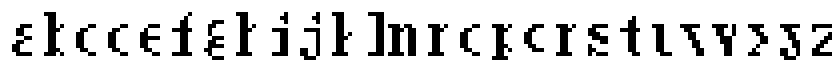


Смещение 1 байт (0x21):
Символы при смещении 1:


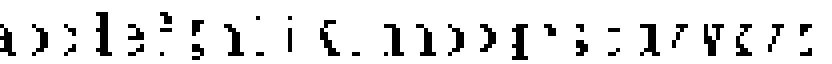


Смещение 2 байт (0x22):
Символы при смещении 2:


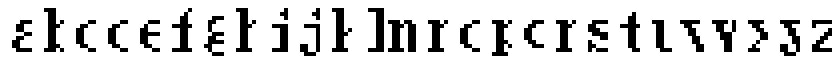

Первые символы в HEX:

Символ 0:
  Строка 0: 00 00
  Строка 1: 00 00
  Строка 2: 00 00
  Строка 3: 00 00

Символ 1:
  Строка 0: 00 00
  Строка 1: 00 00
  Строка 2: 1C 00
  Строка 3: 0C 00

Символ 2:
  Строка 0: 00 00
  Строка 1: 00 00
  Строка 2: 00 00
  Строка 3: 00 00

Символ 3:
  Строка 0: 00 00
  Строка 1: 00 00
  Строка 2: 00 E0
  Строка 3: 00 60

Символ 4:
  Строка 0: 00 00
  Строка 1: 00 00
  Строка 2: 00 00
  Строка 3: 00 00

Смещение 3 байт (0x23):
Символы при смещении 3:


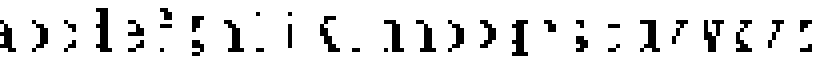


Анализ блока английский (0x620):

Смещение 0 байт (0x620):
Символы при смещении 0:


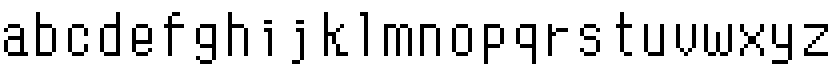


Смещение 1 байт (0x621):
Символы при смещении 1:


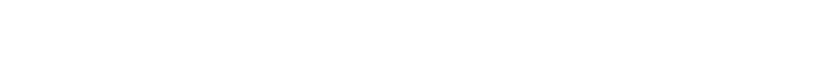


Смещение 2 байт (0x622):
Символы при смещении 2:


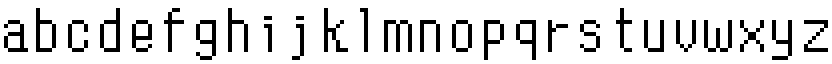

Первые символы в HEX:

Символ 0:
  Строка 0: 00 00
  Строка 1: 00 00
  Строка 2: 00 00
  Строка 3: 00 00

Символ 1:
  Строка 0: 00 00
  Строка 1: 00 00
  Строка 2: 40 00
  Строка 3: 40 00

Символ 2:
  Строка 0: 00 00
  Строка 1: 00 00
  Строка 2: 00 00
  Строка 3: 00 00

Символ 3:
  Строка 0: 00 00
  Строка 1: 00 00
  Строка 2: 04 00
  Строка 3: 04 00

Символ 4:
  Строка 0: 00 00
  Строка 1: 00 00
  Строка 2: 00 00
  Строка 3: 00 00

Смещение 3 байт (0x623):
Символы при смещении 3:


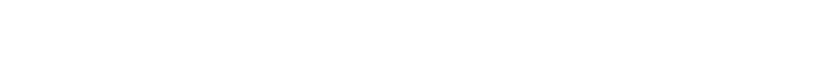

In [49]:
import os
from PIL import Image, ImageDraw
from IPython.display import display

def analyze_with_offset(data, start_offset, block_name):
    """
    Анализирует блок с возможным смещением
    """
    char_size = 32
    char_width = 8
    char_height = 16
    num_chars = 26
    
    print(f"\nАнализ блока {block_name} (0x{start_offset:X}):")
    
    # Создаем изображение для каждого возможного смещения
    for offset_try in range(0, 4):  # Пробуем смещения 0-3 байта
        img = Image.new('1', (char_width * num_chars, char_height), 1)
        pixels = img.load()
        
        actual_start = start_offset + offset_try
        print(f"\nСмещение {offset_try} байт (0x{actual_start:X}):")
        
        for char in range(num_chars):
            col = char * char_width
            
            for row in range(char_height):
                pos = actual_start + char * char_size + row * 2
                if pos + 1 >= len(data):
                    break
                    
                byte = data[pos]
                
                for bit in range(8):
                    if byte & (1 << (7-bit)):
                        x = col + bit
                        y = row
                        if x < img.width and y < img.height:
                            pixels[x, y] = 0
        
        # Увеличиваем для просмотра
        img_resized = img.resize((img.width * 4, img.height * 4), Image.Resampling.NEAREST)
        print(f"Символы при смещении {offset_try}:")
        display(img_resized)
        
        # Показываем первые несколько символов в HEX
        if offset_try == 2:  # Предположительное правильное смещение
            print("Первые символы в HEX:")
            for char in range(5):
                print(f"\nСимвол {char}:")
                for row in range(4):  # Первые 4 строки
                    pos = actual_start + char * char_size + row * 2
                    if pos + 1 < len(data):
                        print(f"  Строка {row}: {data[pos]:02X} {data[pos+1]:02X}")

# Основная часть
with open('Data/FONT.BIN', 'rb') as f:
    data = f.read()

# Анализируем оба блока с разными смещениями
analyze_with_offset(data, 0x0020, "японский/верхний")
analyze_with_offset(data, 0x0620, "английский")

#### Пытаюсь разобрать область `0x0620 - 0x0960` - английский алфавит

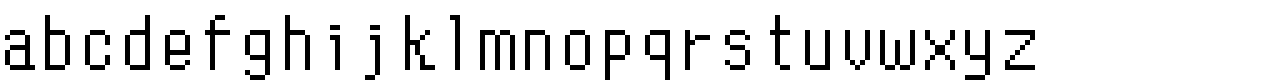

In [40]:
import os
from PIL import Image
from IPython.display import display

with open('Data/FONT.BIN', 'rb') as f:
    data = f.read()

start = 0x620
char_size = 32
char_width = 8
char_height = 16
chars_per_row = 32  # 256 / 8 = 32 символа в строке

# Создаем изображение 256x16 (32 символа * 8 пикселей = 256)
img = Image.new('1', (256, 16), 1)  # 1 - белый фон (mode '1' - черно-белое)
pixels = img.load()

# Рисуем символы с 0 по 25 (все 26 символов)
for char in range(26):  # 0-25
    # Определяем позицию символа на изображении
    row_in_image = 0  # все символы в одной строке, так как высота 16
    col_in_image = char * char_width
    
    for row in range(char_height):  # 16 строк для каждого символа
        pos = start + char * char_size + row * 2
        if pos + 1 >= len(data):
            break
            
        byte = data[pos]  # Берем первый байт (левая половина символа)
        
        # Рисуем 8 пикселей текущей строки
        for col in range(8):
            if byte & (1 << (7-col)):  # Если бит установлен
                x = col_in_image + col
                y = row_in_image + row
                if x < 256 and y < 16:  # Проверяем границы изображения
                    pixels[x, y] = 0  # 0 - черный цвет

img.save('Result/font_output_1.png')

new_width = img.width * 5
new_height = img.height * 5
img_resized = img.resize((new_width, new_height), Image.Resampling.NEAREST)  # NEAREST лучше для пиксельной графики

display(img_resized)

#### В итоге в области позиции 0x620 - 0x960 находится английский алфавит

#### Пытаюсь разобрать область `0x0A80 - 0x0BF0`

In [44]:
# Проверка: интерпретируем как палитру PS1
palette_data = data[0x0A80:0x0A80+32]
for i in range(0, 32, 2):
    color = palette_data[i] | (palette_data[i+1] << 8)
    print(f"Цвет {i//2}: 0x{color:04x}")

Цвет 0: 0x0000
Цвет 1: 0x0000
Цвет 2: 0x0400
Цвет 3: 0x041f
Цвет 4: 0x2407
Цвет 5: 0xa419
Цвет 6: 0x2420
Цвет 7: 0x2404
Цвет 8: 0x2404
Цвет 9: 0xa43f
Цвет 10: 0x2406
Цвет 11: 0x240d
Цвет 12: 0x841c
Цвет 13: 0x0434
Цвет 14: 0x0c04
Цвет 15: 0x0000


In [45]:
from PIL import Image

# Создаем изображение из блока 0x0A80-0x0BF0
block_data = data[0x0A80:0x0BF0]
block_size = len(block_data)

# Пробуем как 8×8 пикселей (1 байт на пиксель)
width = 16  # пробуем разную ширину
height = block_size // width

if height > 0:
    img = Image.new('L', (width, height))
    pixels = img.load()
    
    for y in range(min(height, 100)):
        for x in range(width):
            if y * width + x < block_size:
                pixels[x, y] = block_data[y * width + x]
    
    img.save('Result/block_0A80_as_image.png')
    print(f"Сохранено как изображение {width}x{height}")

Сохранено как изображение 16x23
